# Calibration & Operating Point

Rigor pass 2 on the champion (`HistGradientBoosting`). SMOTE balances the classes by inflating predicted probabilities, an implicit and uncontrolled threshold shift. This notebook asks whether SMOTE actually helps, and chooses the decision threshold from the cost of errors instead of the default 0.5. Logic in `src/calibration.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'
import numpy as np, matplotlib.pyplot as plt
from src import calibration as cal

In [2]:
yte, probs = cal.fit_probabilities()
cal.brier_table(yte, probs)

,model,brier,roc_auc
0,smote,0.1047,0.8600
1,no_smote,0.1015,0.8621
2,no_smote_isotonic,0.1013,0.8607


SMOTE did not improve discrimination (ROC AUC 0.86 either way) and is slightly worse calibrated than the unresampled model; post-hoc calibration adds nothing. SMOTE was an uncontrolled way to shift the operating point, not a free lunch.

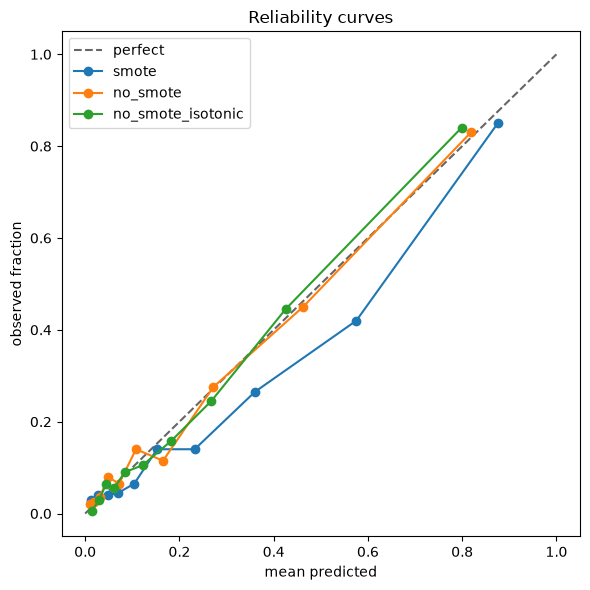

In [3]:
rel = cal.reliability(yte, probs)
plt.figure(figsize=(6,6)); plt.plot([0,1],[0,1],'k--',alpha=.6,label='perfect')
for name,(mean,frac) in rel.items(): plt.plot(mean,frac,marker='o',label=name)
plt.xlabel('mean predicted'); plt.ylabel('observed fraction'); plt.title('Reliability curves')
plt.legend(); plt.tight_layout(); plt.savefig(_root/'results'/'reliability_curve.png',dpi=120); plt.show()

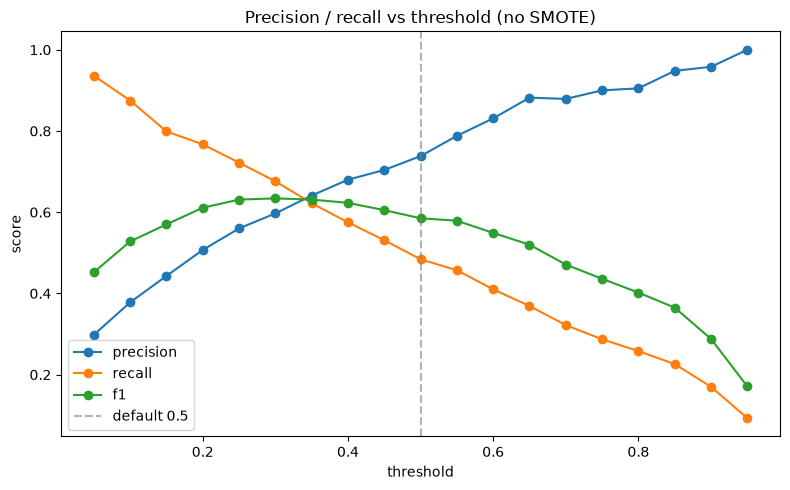

,threshold,precision,recall,f1,flagged
0,0.05,0.298,0.936,0.452,1277
1,0.10,0.378,0.875,0.528,941
2,0.15,0.443,0.799,0.570,734
3,0.20,0.507,0.767,0.611,615
4,0.25,0.560,0.722,0.631,525
5,0.30,0.597,0.676,0.634,461
6,0.35,0.641,0.622,0.631,395
7,0.40,0.680,0.575,0.623,344
8,0.45,0.704,0.531,0.605,307
9,0.50,0.738,0.484,0.585,267


In [4]:
sweep = cal.threshold_sweep(yte, probs['no_smote'])
plt.figure(figsize=(8,5))
for col in ['precision','recall','f1']: plt.plot(sweep['threshold'], sweep[col], marker='o', label=col)
plt.axvline(0.5,color='gray',ls='--',alpha=.6,label='default 0.5')
plt.xlabel('threshold'); plt.ylabel('score'); plt.title('Precision / recall vs threshold (no SMOTE)')
plt.legend(); plt.tight_layout(); plt.savefig(_root/'results'/'threshold_tradeoff.png',dpi=120); plt.show()
sweep

In [5]:
from sklearn.metrics import recall_score, precision_score
p=probs['smote']; pred=(p>=0.5).astype(int)
print(f"smote @0.5 (pass-1 style): recall={recall_score(yte,pred):.3f} precision={precision_score(yte,pred):.3f}")
print('cost FN:FP = 3:1 :', cal.threshold_by_cost(yte, probs['no_smote'], 3, 1))
print('cost FN:FP = 5:1 :', cal.threshold_by_cost(yte, probs['no_smote'], 5, 1))

smote @0.5 (pass-1 style): recall=0.590 precision=0.674
cost FN:FP = 3:1 : {'threshold': 0.26, 'cost': 563.0, 'fn': 113, 'fp': 224, 'recall': 0.722, 'precision': 0.568}
cost FN:FP = 5:1 : {'threshold': 0.21, 'cost': 773.0, 'fn': 97, 'fp': 288, 'recall': 0.762, 'precision': 0.518}


The unresampled model with an explicit cost-based threshold recovers (and exceeds) SMOTE's recall while keeping the choice transparent. Churn is asymmetric: losing a customer usually costs more than a retention offer, so a 3:1 or 5:1 cost ratio is reasonable. See `docs/learnings.md`.